# Interpolated temperature maps

This tutorial shows how to compute pulse profiles for a star whose surface temperature is given as a **map on a grid of colatitudes and azimuths**, for example from a numerical simulation. X-PSI interpolates the map onto its own surface mesh using the [Everywhere](everywhere.rst#xpsi.Everywhere.Everywhere) class (see also the [Global surface emission](Global_surface_emission.ipynb) tutorial for the basics of ``Everywhere``). This functionality is available since X-PSI v3.3.0.

As an example, we use a time-averaged temperature map of the accretion hotspots from the general-relativistic magnetohydrodynamic (GRMHD) simulations of [Das et al. (2025)](https://doi.org/10.3847/1538-4357/add472), for a star whose magnetic axis is inclined by $\chi_\star = 90^\circ$ from the rotation axis. We then reproduce their normalised bolometric pulse profiles for different observer inclinations (their Figure 4c) and the corresponding pulse amplitudes (their Figure 5).

## The temperature map

The map used here is available in [Zenodo](https://zenodo.org/records/7113931) as ``average_temp_inc90.npz``. Download it and place it in the directory ``examples/examples_modeling_tutorial/model_data/`` of your local X-PSI directory.

The file contains the simulation output on a spherical shell at the stellar surface ($r = 4.3\,r_\mathrm{g}$, where $r_\mathrm{g} = GM/c^2$), averaged over the simulation time $t \in [15000, 25000]\,r_\mathrm{g}/c$ (about 47 stellar rotations). The arrays are given on a $512 \times 512$ grid:

* ``theta``: colatitude, from $0$ to $\pi$,
* ``phi``: azimuth, from $-\pi$ to $\pi$,
* ``flux``: the matter-energy flux through the shell (in simulation units),
* ``tracer``: a simulation quantity that is not used by X-PSI.

In [1]:
%matplotlib inline

import os
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson

import xpsi
from xpsi.global_imports import _c, _kpc, _km, gravradius
from xpsi.shell_interpolator import Temp_Interpolator_shells

/=============================================\
| X-PSI: X-ray Pulse Simulation and Inference |
|---------------------------------------------|
|               Version: 3.5.0b1              |
|---------------------------------------------|
|      https://xpsi-group.github.io/xpsi      |
\=============================================/

Imported emcee version: 3.1.6
Imported PyMultiNest.
Imported UltraNest.
Imported GetDist version: 1.7.7
Imported nestcheck version: 0.2.1


In [2]:
filename = '../../examples/examples_modeling_tutorial/model_data/average_temp_inc90.npz'

if not os.path.isfile(filename):
    raise FileNotFoundError(f'{filename} not found: download it from Zenodo (see above).')

## How X-PSI reads and interpolates the map

The interpolation is switched on with ``use_interpolated_temperature=True`` when creating the ``Everywhere`` object. The relevant options are:

* ``filename``: the map file. Supported formats are ``.npz`` files with the arrays ``theta``, ``phi`` and either ``flux`` or ``temp``, and ``.csv`` or ``.txt`` files with the columns ``theta``, ``phi`` and ``temp``.
* ``coderes``: the size of the input grid; the file must contain ``coderes`` $\times$ ``coderes`` points.
* ``bhac_data``: if ``True`` (default), the temperature is computed from the ``flux`` array of a [BHAC](https://gitlab.itp.uni-frankfurt.de/BHAC-release/bhac) simulation, assuming that all the matter-energy flux is emitted as blackbody radiation at the surface, $T = (F/\sigma_\mathrm{SB})^{1/4}$ (Das et al. 2025, Eq. 12). The simulation units are converted to physical units assuming a stellar radius of $R_\star = 4\,r_\mathrm{g} = 10$ km and a mass accretion rate of 1% of the Eddington rate with a radiative efficiency of 0.1. If ``False``, the ``temp`` array (or column) is read directly as temperatures in Kelvin; use this for your own maps.
* ``T_everywhere``: a floor for the interpolated temperatures, in $\log_{10}$ K. This mostly affects the regions outside the hotspots.

X-PSI then interpolates the $\log_{10}$ temperatures onto its own surface mesh (cubic interpolation in colatitude and azimuth). Since the map depends on azimuth, the signal must be computed with ``time_invariant=False``. The usual ``temperature`` parameter of ``Everywhere`` is not used when the interpolation is switched on, so we simply fix it.

## Setting up the star

The simulation is in units of $r_\mathrm{g}$ and $c$, with a stellar radius of $R_\star = 4\,r_\mathrm{g}$ and an angular velocity of $\Omega_\star = 0.03\,c/r_\mathrm{g}$. Like Das et al. (2025), we assume $R_\star = 10$ km, which sets the mass and spin frequency. The equatorial radius used for the ray tracing is the radius of the shell, $R_\mathrm{eq} = 4.3\,r_\mathrm{g}$. The distance only scales the flux and does not affect the normalised pulse profiles.

In [3]:
r_g = 10.0 / 4.0                       # gravitational radius [km] for R_star = 10 km
mass = r_g / gravradius(1.0)           # [solar masses]
radius = 4.3 * r_g                     # equatorial radius [km]
frequency = 0.03 * _c / (2.0 * math.pi * r_g * _km)   # spin frequency [Hz]
distance = 0.2                         # [kpc]

print(f'M = {mass:.3f} M_sun, R_eq = {radius:.2f} km, f = {frequency:.2f} Hz')

M = 1.693 M_sun, R_eq = 10.75 km, f = 572.56 Hz


In [4]:
spacetime = xpsi.Spacetime(bounds=dict(distance=(0.1, 1.0),
                                       mass=(1.0, 3.0),
                                       radius=(3.0 * gravradius(1.0), 16.0),
                                       cos_inclination=(0.0, 1.0)),
                           values=dict(frequency=frequency))

everywhere = xpsi.Everywhere(time_invariant=False,
                             values=dict(temperature=6.0),   # not used with interpolation
                             sqrt_num_cells=256,
                             num_rays=256,
                             num_leaves=64,
                             use_interpolated_temperature=True,
                             filename=filename,
                             coderes=512,
                             bhac_data=True,
                             T_everywhere=5.0)

photosphere = xpsi.Photosphere(hot=None, elsewhere=None, everywhere=everywhere,
                               values=dict(mode_frequency=spacetime['frequency']))

star = xpsi.Star(spacetime=spacetime, photospheres=photosphere)

Creating parameter:
    > Named "frequency" with fixed value 5.726e+02.
    > Spin frequency [Hz].
Creating parameter:
    > Named "mass" with bounds [1.000e+00, 3.000e+00].
    > Gravitational mass [solar masses].
Creating parameter:
    > Named "radius" with bounds [4.430e+00, 1.600e+01].
    > Coordinate equatorial radius [km].
Creating parameter:
    > Named "distance" with bounds [1.000e-01, 1.000e+00].
    > Earth distance [kpc].
Creating parameter:
    > Named "cos_inclination" with bounds [0.000e+00, 1.000e+00].
    > Cosine of Earth inclination to rotation axis.
Creating parameter:
    > Named "temperature" with fixed value 6.000e+00.
    > log10(effective temperature [K] everywhere).
Creating parameter:
    > Named "phase_shift" with fixed value 0.000e+00.
Creating parameter:
    > Named "mode_frequency" with fixed value 5.726e+02.
    > Coordinate frequency of the mode of radiative asymmetry in the
photosphere that is assumed to generate the pulsed signal [Hz].


We first compute the signal for an observer inclination of $i_\mathrm{obs} = 60^\circ$. The parameter vector contains the mass, equatorial radius, distance and cosine of the observer inclination. The energy grid covers the same range as in Das et al. (2025).

In [5]:
star([mass, radius, distance, math.cos(math.radians(60.0))])
star.update()

energies = np.logspace(np.log10(0.01), np.log10(50.87), 100)  # [keV]
photosphere.integrate(energies, threads=4)

## The input and the interpolated map

Let us compare the temperature map in the file with the map interpolated onto the X-PSI mesh. We read the file with the same tool X-PSI uses internally. The two hotspots form elongated bands close to the equator, as expected for $\chi_\star = 90^\circ$ (compare with Figure 2c of Das et al. 2025).

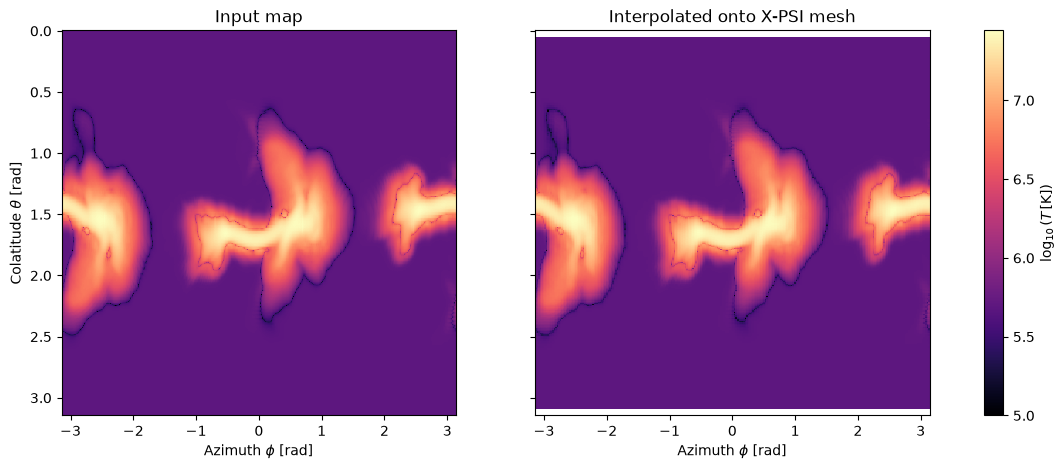

In [6]:
reader = Temp_Interpolator_shells(filename=filename, coderes=512)
theta_in, phi_in, logT_in = reader.read_average_shell(bhac_shell_avg=True)

logT_xpsi = everywhere._cellParamVecs[:, :, 0]

# Both grids are regular in colatitude and azimuth, so we plot them with 1D coordinates.
# (In the input file, all points of the pole row theta = 0 have phi = 0, so we take
# the azimuths from the equator row.)
maps = [(phi_in[phi_in.shape[0] // 2], theta_in[:, 0], logT_in, 'Input map'),
        (everywhere._phi[0], everywhere._theta[:, 0], logT_xpsi, 'Interpolated onto X-PSI mesh')]

vmin, vmax = 5.0, max(logT_in.max(), logT_xpsi.max())
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (phi, theta, logT, title) in zip(axes, maps):
    im = ax.pcolormesh(phi, theta, logT, vmin=vmin, vmax=vmax, cmap='magma',
                       shading='nearest', rasterized=True)
    ax.set_title(title)
    ax.set_xlabel(r'Azimuth $\phi$ [rad]')
axes[0].set_ylabel(r'Colatitude $\theta$ [rad]')
axes[0].invert_yaxis()
fig.colorbar(im, ax=axes, label=r'$\log_{10}(T\,[\mathrm{K}])$')
plt.show()

Note that values below ``T_everywhere`` in the input map are set to the floor after the interpolation.

## Bolometric pulse profile

The photosphere signal is given in photons/s/keV for each energy and phase. We integrate it over energy and divide by the distance squared to get the bolometric photon flux.

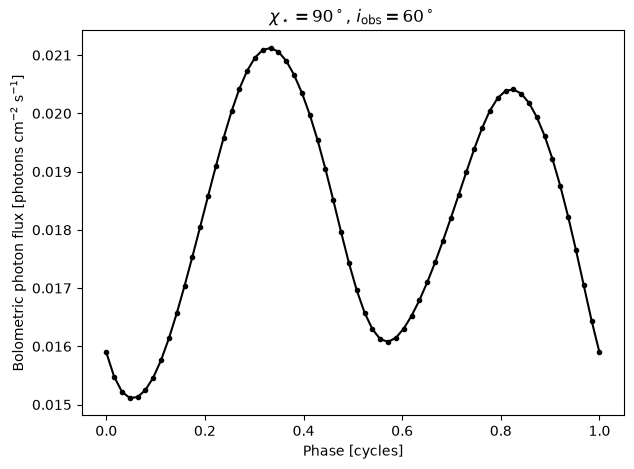

In [7]:
def bolometric_flux(photosphere, energies, distance):
    # Photon flux [photons/cm^2/s] integrated over the energy grid.
    D_cm = distance * _kpc * 100.0
    return simpson(photosphere.signal[0][0], x=energies, axis=0) / D_cm**2

phases = everywhere.phases_in_cycles
flux = bolometric_flux(photosphere, energies, distance)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(phases, flux, 'o-', color='k', markersize=3)
ax.set_xlabel('Phase [cycles]')
ax.set_ylabel(r'Bolometric photon flux [photons cm$^{-2}$ s$^{-1}$]')
ax.set_title(r'$\chi_\star = 90^\circ$, $i_\mathrm{obs} = 60^\circ$')
plt.show()

## Pulse profiles for different observer inclinations

Next we compute the pulses for observer inclinations from $10^\circ$ to $90^\circ$, normalised to their maxima, to reproduce Figure 4c of Das et al. (2025). Only the inclination changes, so the temperature map does not need to be interpolated again.

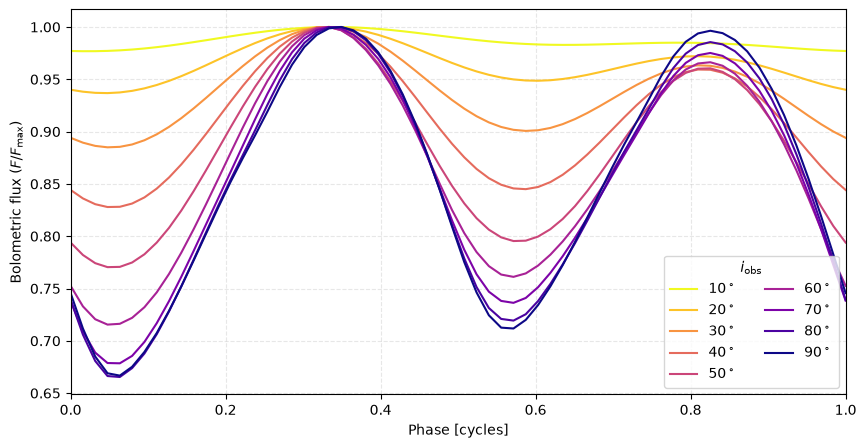

In [8]:
inclinations = np.arange(10, 91, 10)
pulses = {}

for i_obs in inclinations:
    star['cos_inclination'] = math.cos(math.radians(i_obs))
    star.update()
    photosphere.integrate(energies, threads=4)
    pulses[i_obs] = bolometric_flux(photosphere, energies, distance)

colors = plt.cm.plasma_r(np.linspace(0, 1, len(inclinations)))
fig, ax = plt.subplots(figsize=(10, 5))
for i_obs, color in zip(inclinations, colors):
    ax.plot(phases, pulses[i_obs] / pulses[i_obs].max(), color=color, label=fr'${i_obs}^\circ$')
ax.set_xlabel('Phase [cycles]')
ax.set_ylabel(r'Bolometric flux ($F/F_\mathrm{max}$)')
ax.set_xlim(0, 1)
ax.grid(linestyle='--', alpha=0.3)
ax.legend(title=r'$i_\mathrm{obs}$', ncol=2, loc='lower right')
plt.show()

As in Das et al. (2025), both hotspots are close to the equator and visible at almost all phases, so the pulse amplitudes are small and the profiles have two peaks per rotation, especially at high inclinations.

## Pulse amplitudes

To quantify this, we fit each pulse with a fundamental and a first harmonic, $f(\phi) = A + B\sin(2\pi\phi + \phi_1) + C\sin(4\pi\phi + \phi_2)$, and compute the fractional rms amplitudes $B/(A\sqrt{2})$ and $C/(A\sqrt{2})$ (Das et al. 2025, Eq. 14 and Figure 5). The fit is linear when written with sines and cosines.

 i_obs   fundamental   first harmonic
   10        0.0059           0.0039
   20        0.0113           0.0153
   30        0.0155           0.0330
   40        0.0181           0.0554
   50        0.0196           0.0790
   60        0.0223           0.0994
   70        0.0231           0.1138
   80        0.0209           0.1213
   90        0.0184           0.1236


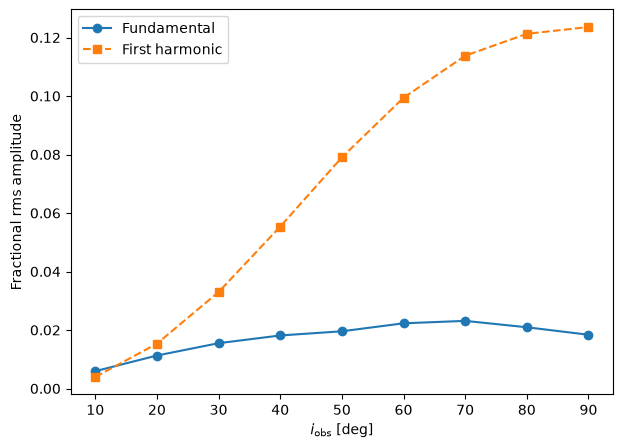

In [9]:
def rms_amplitudes(phases, pulse):
    # Fractional rms amplitudes of the fundamental and the first harmonic.
    x = 2.0 * np.pi * phases
    design = np.column_stack([np.ones_like(x), np.sin(x), np.cos(x), np.sin(2*x), np.cos(2*x)])
    A, b1, b2, c1, c2 = np.linalg.lstsq(design, pulse, rcond=None)[0]
    return np.hypot(b1, b2) / (A * np.sqrt(2)), np.hypot(c1, c2) / (A * np.sqrt(2))

# The last phase point repeats the first one (phase 1 = phase 0), so it is left out of the fit.
rms = np.array([rms_amplitudes(phases[:-1], pulses[i][:-1]) for i in inclinations])

print(' i_obs   fundamental   first harmonic')
for i_obs, (r1, r2) in zip(inclinations, rms):
    print(f'{i_obs:5d}   {r1:11.4f}   {r2:14.4f}')

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(inclinations, rms[:, 0], 'o-', label='Fundamental')
ax.plot(inclinations, rms[:, 1], 's--', label='First harmonic')
ax.set_xlabel(r'$i_\mathrm{obs}$ [deg]')
ax.set_ylabel('Fractional rms amplitude')
ax.legend()
plt.show()

The results follow those of Das et al. (2025) for $\chi_\star = 90^\circ$ (green curves in their Figure 5): the first-harmonic amplitude grows strongly with the observer inclination, up to about 0.12, while the fundamental amplitude stays at about 0.02 or below. The values agree within about 10%. Small differences are expected, because the numerical settings (e.g. the mesh resolution) and the X-PSI version differ from the paper. Note also that the phase zero point is arbitrary, so the pulses may be shifted in phase compared to the paper.

## Notes and caveats

* The map is a time average. In the simulations, the hotspots vary in time, and pulses computed from the time-averaged map can differ by about 10% from the average of time-resolved pulses (Das et al. 2025, Section 3.2.2).
* The emission is assumed to be isotropic blackbody radiation; there is no atmosphere model or electron scattering in this example. Das et al. (2025) studied the effects of electron scattering with the RAPTOR code.
* To use your own temperature map, save it in one of the formats above with temperatures in Kelvin and set ``bhac_data=False``.

### Reference

P. Das, T. Salmi, J. Davelaar, O. Porth, and A. Watts, *Pulse Profiles of Accreting Neutron Stars from GRMHD Simulations*, ApJ **987**, 34 (2025), [doi:10.3847/1538-4357/add472](https://doi.org/10.3847/1538-4357/add472).